# Case Study 15 — Branch Loan Processing Times and a New Workflow

**Choosing between parametric and non-parametric tests · Kruskal-Wallis and Dunn's post-hoc test with Holm correction ·
ANOVA on raw vs log data · rank-based effect sizes (ε², probability of superiority) · paired t-test vs Wilcoxon
signed-rank vs sign test vs sign-flip permutation · Hodges-Lehmann estimate · bootstrap CI for a median · power under
different distributions**

| | |
|---|---|
| **Domain** | Retail lending operations |
| **Stakeholders** | Head of Lending Operations, Process Excellence lead |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 02 (two-group tests), Case 14 (ANOVA) |
| **Data** | (A) 190 loans from 5 branches; (B) 20 loan officers before and after a new workflow |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. Why small, skewed samples with outliers can make the usual tests (ANOVA, t-test) **miss** clear effects.
2. What Kruskal-Wallis, Mann-Whitney, Wilcoxon and the sign test actually test, and what they **do not** test.
3. How to choose between a parametric and a non-parametric test on purpose: by the **question** (mean or typical
   value?), the **data** (shape, outliers, n) and the **design** (independent or paired).

## Section 1 — Business context

You are a data scientist working with **Lending Operations**. Personal-loan customers complain that disbursement takes
too long, and branches report very different turnaround times. Two questions arrive at once:

> *"(A) Do our five Mumbai-region branches really differ in processing time, or is it noise? Last quarter's numbers
> are all over the place. (B) We piloted a new digital document workflow with 20 loan officers. Their average
> processing time fell by less than half a day and the analyst says it's 'not significant'. Should we drop it?"*

Processing time is measured in days from application to disbursement. Most loans take about a week, but some get
"stuck" (missing documents) and take one to two months.

## Section 2 — Business questions

1. Do the five branches differ in processing time? Which ones?
2. How big are the differences, in days and in "how often is one branch faster"?
3. Did the new workflow reduce processing time for the pilot officers? By how much?
4. Which tests should Operations use for this kind of data in future?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Methods compared |
|---|---|---|---|
| 1 | Branches differ? | Do the distributions (typical times) differ across 5 independent groups? | One-way ANOVA, Welch ANOVA, ANOVA on log times, **Kruskal-Wallis** |
| 1b | Which branches? | Pairwise comparisons with error control | Games-Howell vs **Dunn + Holm** |
| 2 | How big? | Median differences; P(random loan at A is slower than at B) | Medians with bootstrap CIs; probability of superiority; ε² |
| 3 | Workflow helped? | Is the **paired** change different from 0? | Paired t, **Wilcoxon signed-rank**, sign test, sign-flip permutation; Hodges-Lehmann estimate |
| 4 | Which tests in future? | Type I error and power of each test for this kind of data | Simulation |

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "15_branch_processing_nonparametric"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1515)
ORDER = ["Andheri", "Borivali", "Vashi", "Thane", "Panvel"]
B_COL = dict(zip(ORDER, [COLORS["blue"], COLORS["aqua"], COLORS["violet"], COLORS["orange"], COLORS["red"]]))

## Section 4 — Load the data

In [2]:
loans = pd.read_csv(PATHS["data"] / "branch_processing_times.csv")
pilot = pd.read_csv(PATHS["data"] / "workflow_pilot.csv")
print(f"(A) {len(loans)} loans; missing {loans.isna().sum().sum()};  (B) {len(pilot)} officers; missing {pilot.isna().sum().sum()}")
loans["branch"] = pd.Categorical(loans["branch"], categories=ORDER)
display(loans.head())
display(pilot.head())

(A) 190 loans; missing 0;  (B) 20 officers; missing 0


,loan_id,branch,processing_days
0,PL1510000,Vashi,6.3000
1,PL1510001,Andheri,6.6000
2,PL1510002,Borivali,4.4000
3,PL1510003,Thane,6.3000
4,PL1510004,Thane,7.2000


,officer_id,days_before,days_after
0,LO101,7.1000,5.9000
1,LO102,7.5000,6.6000
2,LO103,8.3000,7.9000
3,LO104,7.2000,7.1000
4,LO105,9.9000,10.3000


## Part A — Do the branches differ?

### Section 5 — Descriptive statistics

In [3]:
def boot_median_ci(x, n=4000):
    meds = np.median(rng.choice(x, (n, len(x))), axis=1)
    return np.percentile(meds, [2.5, 97.5])

rows = []
for b in ORDER:
    x = loans.loc[loans["branch"] == b, "processing_days"].to_numpy()
    lo, hi = boot_median_ci(x)
    rows.append({"branch": b, "n": len(x), "mean": x.mean(), "sd": x.std(ddof=1), "median": np.median(x),
                 "median ci_low": lo, "median ci_high": hi, "share over 20 days": (x > 20).mean(),
                 "skewness": stats.skew(x)})
desc = pd.DataFrame(rows).set_index("branch")
save_table(desc, "branch_summary", PATHS["tables"])
desc

,n,mean,sd,median,median ci_low,median ci_high,share over 20 days,skewness
branch,,,,,,,,
Andheri,42,9.2167,11.4545,6.0000,5.3500,7.1500,0.0714,3.5816
Borivali,38,8.1263,10.3814,6.9500,5.1000,7.6000,0.0263,5.4453
Vashi,30,9.1900,10.2339,6.2500,4.6500,8.0000,0.0667,2.8531
Thane,45,14.4467,16.3809,7.8000,7.0000,10.2000,0.1111,2.2894
Panvel,35,12.4486,8.2092,10.4000,8.3000,13.0000,0.0857,3.1911


**Observation.** Typical (median) processing time ranges from about 6 days (Andheri, Vashi) to about 10 days (Panvel).
The **means** are much higher than the medians and their order is different (Thane has the highest mean), because a
few stuck loans of 40–70 days dominate them. Every branch's data is strongly right-skewed, and the groups are small
(30–45 loans).

**Which number answers the business question?** Customers and branch managers experience the **typical** loan; the
stuck loans are a separate problem (document chasing). The **median**, and tests about typical values, fit the
question better than the mean here. That choice comes first; the test follows from it.

### Section 6 — Visualisation

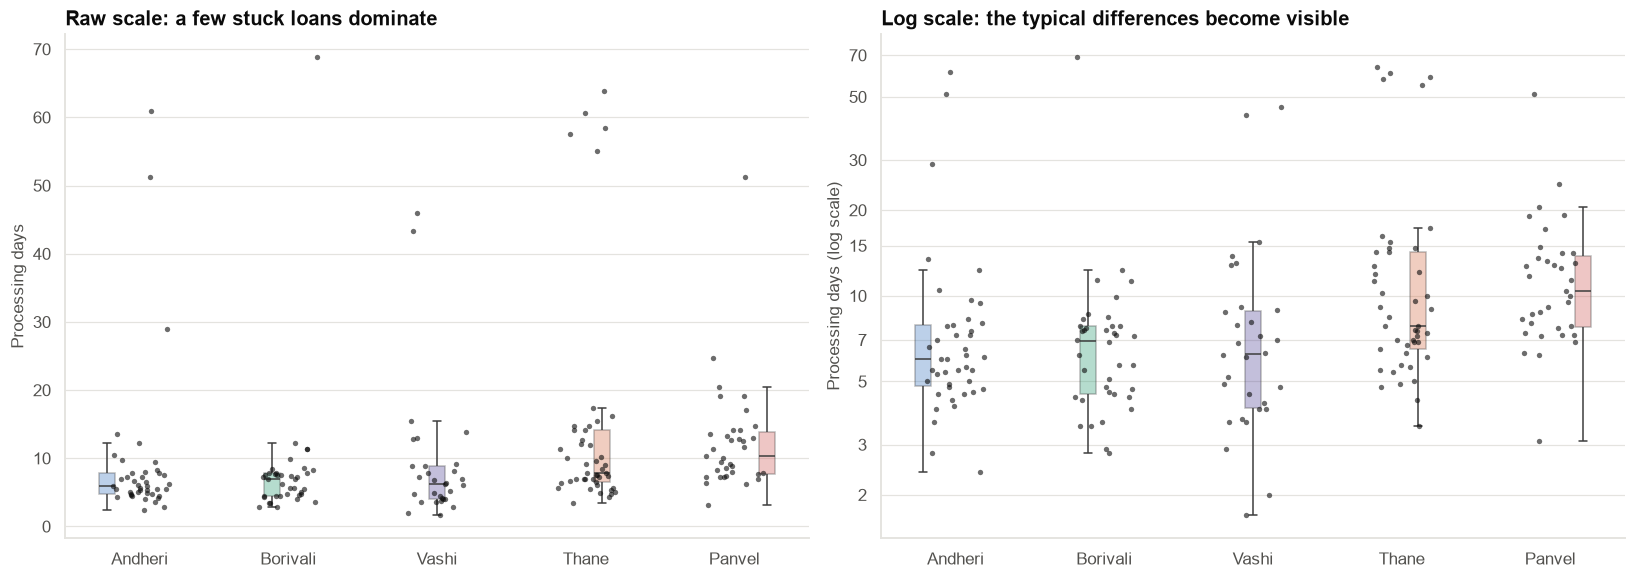

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
ax = axes[0]
sns.boxplot(data=loans, x="branch", y="processing_days", order=ORDER, ax=ax, hue="branch", hue_order=ORDER, palette=B_COL,
            legend=False, width=0.55, fliersize=0, boxprops=dict(alpha=0.35))
sns.stripplot(data=loans, x="branch", y="processing_days", order=ORDER, ax=ax, color=INK, size=3.5, alpha=0.6, jitter=0.2)
ax.set(xlabel="", ylabel="Processing days", title="Raw scale: a few stuck loans dominate")
ax = axes[1]
sns.boxplot(data=loans, x="branch", y="processing_days", order=ORDER, ax=ax, hue="branch", hue_order=ORDER, palette=B_COL,
            legend=False, width=0.55, fliersize=0, boxprops=dict(alpha=0.35))
sns.stripplot(data=loans, x="branch", y="processing_days", order=ORDER, ax=ax, color=INK, size=3.5, alpha=0.6, jitter=0.2)
ax.set_yscale("log")
ax.set_yticks([2, 3, 5, 7, 10, 15, 20, 30, 50, 70], ["2", "3", "5", "7", "10", "15", "20", "30", "50", "70"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set(xlabel="", ylabel="Processing days (log scale)", title="Log scale: the typical differences become visible")
fig.tight_layout()
save_fig(fig, "fig01_branch_times", PATHS["figures"])
plt.show()

**Observation.** On the raw scale, the boxes are squashed at the bottom by stuck loans. On the log scale, Panvel and
Thane are visibly slower in their typical loans than Andheri, Borivali and Vashi, with each branch having a few stuck
loans far above the rest.

### Section 7 — Method selection

| Option | Tests | Assumes | Here |
|---|---|---|---|
| One-way ANOVA | equal **means** | normal-ish data, equal variances | ❌ Means dominated by stuck loans; variances inflated by outliers |
| Welch ANOVA | equal **means** | unequal variances OK | ⚠️ Same estimand (means); still outlier-driven |
| ANOVA on log(days) | equal **geometric means** | log-normal-ish | ✅ Reasonable if the log removes the skew |
| **Kruskal-Wallis** | no group tends to have larger values than the others (stochastic equality); a test of medians only if shapes are similar | independent groups, ordinal or continuous data | ✅ Robust to outliers and skew; uses ranks |

**What rank tests really test.** Kruskal-Wallis (and Mann-Whitney for two groups) compares the **ranks** of the
values: "is a loan from one branch likely to take longer than a loan from another?". It is a test of **medians**
only if the distributions have the same shape and spread. With similar shapes (as here, broadly), "typical time
differs" is a fair summary.

### Section 8 — Running all four tests

In [5]:
groups = [loans.loc[loans["branch"] == b, "processing_days"].to_numpy() for b in ORDER]
an = stats.f_oneway(*groups)
we = anova_oneway(loans["processing_days"], loans["branch"], use_var="unequal")
lg = stats.f_oneway(*[np.log(g) for g in groups])
kw = stats.kruskal(*groups)
N, k = len(loans), len(ORDER)
eps2 = (kw.statistic - k + 1) / (N - k)                     # rank-based effect size (epsilon squared)
tests = pd.DataFrame({"statistic": [an.statistic, we.statistic, lg.statistic, kw.statistic],
                      "p_value": [an.pvalue, we.pvalue, lg.pvalue, kw.pvalue],
                      "what it compares": ["means", "means (unequal variances)", "geometric means", "rank distributions (typical values)"]},
                     index=["One-way ANOVA (raw days)", "Welch ANOVA (raw days)", "ANOVA on log(days)", "Kruskal-Wallis"])
save_table(tests, "branch_tests", PATHS["tables"])
display(tests)
print(f"Kruskal-Wallis effect size ε² = {eps2:.3f}")

,statistic,p_value,what it compares
One-way ANOVA (raw days),2.0036,0.0958,means
Welch ANOVA (raw days),1.8561,0.1250,means (unequal variances)
ANOVA on log(days),5.9602,0.0002,geometric means
Kruskal-Wallis,33.6490,0.0000,rank distributions (typical values)


Kruskal-Wallis effect size ε² = 0.160


**Observation.** On the raw data, ANOVA does **not** find a difference (p ≈ 0.10), and Welch ANOVA gives a weaker
result than the rank and log tests. Kruskal-Wallis is overwhelming (p ≈ 10⁻⁶), and ANOVA on log times agrees
(p < 0.001).

**Interpretation.** The stuck loans add huge, random variance to every branch. ANOVA compares **means** and measures
noise with the **variance**, so a handful of 50-day loans both blur the means and inflate the noise estimate. Ranks
cap the influence of any single loan: a 60-day loan is simply "the slowest", whatever its value. The typical
processing times clearly differ.

> **Same data, opposite conclusions.** ANOVA says "no evidence", Kruskal-Wallis says "overwhelming evidence". Neither
> is wrong; they answer different questions with different robustness. Choosing the test **after** seeing which one
> is significant would be p-hacking. Choose it from the question and the data's shape (Section 7), before testing.

### Section 9 — Which branches differ? Dunn's test with Holm correction

In [6]:
def dunn_test(df, group, value, order):
    r = stats.rankdata(df[value])
    df = df.assign(_r=r)
    N_ = len(df)
    ties = np.unique(r, return_counts=True)[1]
    tie_corr = (ties ** 3 - ties).sum() / (12 * (N_ - 1))
    g = df.groupby(group, observed=True)["_r"].agg(["mean", "size"])
    rows = []
    for a, b in combinations(order, 2):
        se = np.sqrt((N_ * (N_ + 1) / 12 - tie_corr) * (1 / g.loc[a, "size"] + 1 / g.loc[b, "size"]))
        z = (g.loc[a, "mean"] - g.loc[b, "mean"]) / se
        xa = df.loc[df[group] == a, value].to_numpy(); xb = df.loc[df[group] == b, value].to_numpy()
        ps = (xa[:, None] > xb[None, :]).mean() + 0.5 * (xa[:, None] == xb[None, :]).mean()
        rows.append({"branch A": a, "branch B": b, "median A": np.median(xa), "median B": np.median(xb),
                     "P(loan at A slower than at B)": ps, "z": z, "p_raw": 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    out["p_holm"] = multipletests(out["p_raw"], method="holm")[1]
    out["significant (Holm, 5%)"] = out["p_holm"] < 0.05
    return out

dunn = dunn_test(loans, "branch", "processing_days", ORDER)
save_table(dunn.set_index(["branch A", "branch B"]), "dunn_posthoc", PATHS["tables"])
dunn

,branch A,branch B,median A,median B,P(loan at A slower than at B),z,p_raw,p_holm,"significant (Holm, 5%)"
0,Andheri,Borivali,6.0000,6.9500,0.4987,0.0325,0.9741,1.0000,False
1,Andheri,Vashi,6.0000,6.2500,0.5119,-0.1543,0.8773,1.0000,False
2,Andheri,Thane,6.0000,7.8000,0.2960,-3.1547,0.0016,0.0112,True
3,Andheri,Panvel,6.0000,10.4000,0.1983,-4.4749,0.0000,0.0001,True
4,Borivali,Vashi,6.9500,6.2500,0.4974,-0.1809,0.8565,1.0000,False
5,Borivali,Thane,6.9500,7.8000,0.3047,-3.1053,0.0019,0.0114,True
6,Borivali,Panvel,6.9500,10.4000,0.1853,-4.4026,0.0000,0.0001,True
7,Vashi,Thane,6.2500,7.8000,0.3196,-2.7151,0.0066,0.0331,True
8,Vashi,Panvel,6.2500,10.4000,0.2462,-3.9680,0.0001,0.0006,True
9,Thane,Panvel,7.8000,10.4000,0.3968,-1.5410,0.1233,0.4933,False


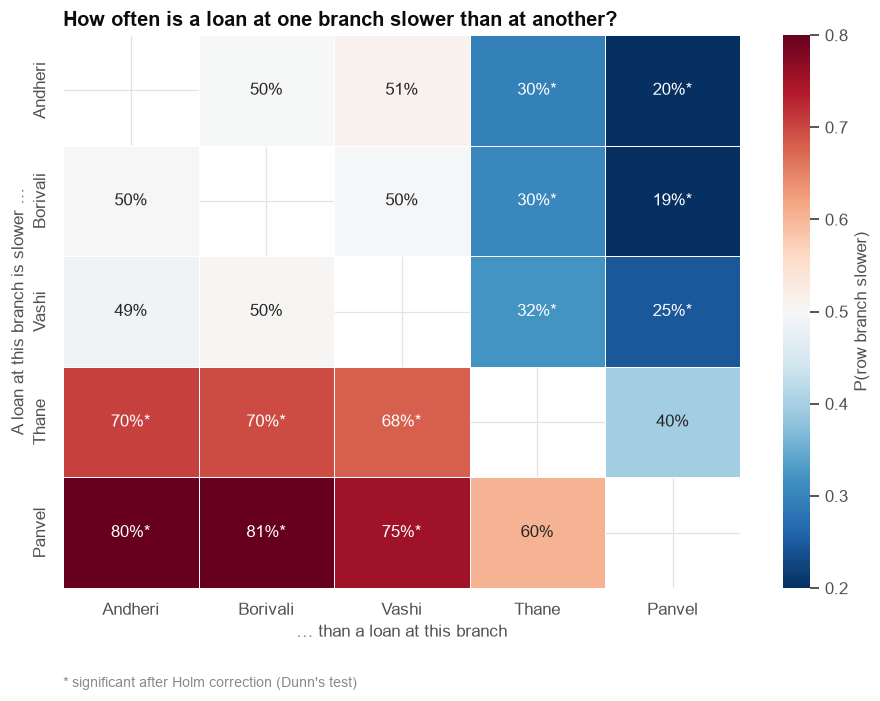

In [7]:
mat = pd.DataFrame(np.nan, index=ORDER, columns=ORDER)
sig = pd.DataFrame("", index=ORDER, columns=ORDER)
for _, r in dunn.iterrows():
    mat.loc[r["branch A"], r["branch B"]] = r["P(loan at A slower than at B)"]
    mat.loc[r["branch B"], r["branch A"]] = 1 - r["P(loan at A slower than at B)"]
    star = "*" if r["significant (Holm, 5%)"] else ""
    sig.loc[r["branch A"], r["branch B"]] = sig.loc[r["branch B"], r["branch A"]] = star
annot = mat.apply(lambda col: col.map(lambda v: "" if np.isnan(v) else f"{v:.0%}")) + sig
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(mat, annot=annot, fmt="", cmap="RdBu_r", vmin=0.2, vmax=0.8, center=0.5, ax=ax, cbar_kws={"label": "P(row branch slower)"},
            linewidths=0.5, linecolor="white")
ax.set(xlabel="… than a loan at this branch", ylabel="A loan at this branch is slower …",
       title="How often is a loan at one branch slower than at another?")
add_note(ax, "* significant after Holm correction (Dunn's test)", (0.0, -0.16, "left", "top"))
fig.tight_layout()
save_fig(fig, "fig02_pairwise_superiority", PATHS["figures"])
plt.show()

**Observation.** Panvel and Thane are slower than Andheri, Borivali and Vashi: a loan at Panvel takes longer than a
loan at one of those three branches 75–81% of the time; for Thane, about 68–70%. All six of these pairs are significant
after the Holm correction for 10 comparisons. Andheri, Borivali and Vashi do not differ from each other, and Panvel vs
Thane is not clearly different.

**Interpretation.**
- **Dunn's test** is the standard follow-up to Kruskal-Wallis: it compares mean ranks using the ranks from **all**
  groups (consistent with the omnibus test). **Holm's** correction controls the family-wise error and is always at
  least as powerful as Bonferroni (Case 19).
- The **probability of superiority** (the share of loan pairs in which A is slower) is the natural effect size for a
  rank test and is easy to explain: 50% = no difference; 75% = A is slower three times out of four.

## Part B — Did the new workflow help?

### Section 10 — The paired data

,officer_id,days_before,days_after,change,pct_change
15,LO116,15.0000,11.5000,-3.5000,-23.3300
12,LO113,9.1000,6.4000,-2.7000,-29.6700
18,LO119,9.4000,6.8000,-2.6000,-27.6600
17,LO118,8.9000,6.8000,-2.1000,-23.6000
5,LO106,8.5000,6.4000,-2.1000,-24.7100
9,LO110,8.5000,6.7000,-1.8000,-21.1800
13,LO114,8.0000,6.2000,-1.8000,-22.5000
8,LO109,11.8000,10.3000,-1.5000,-12.7100
11,LO112,6.1000,4.8000,-1.3000,-21.3100
0,LO101,7.1000,5.9000,-1.2000,-16.9000


Mean change -0.41 days; median change -1.10 days; officers who got faster: 18 of 20


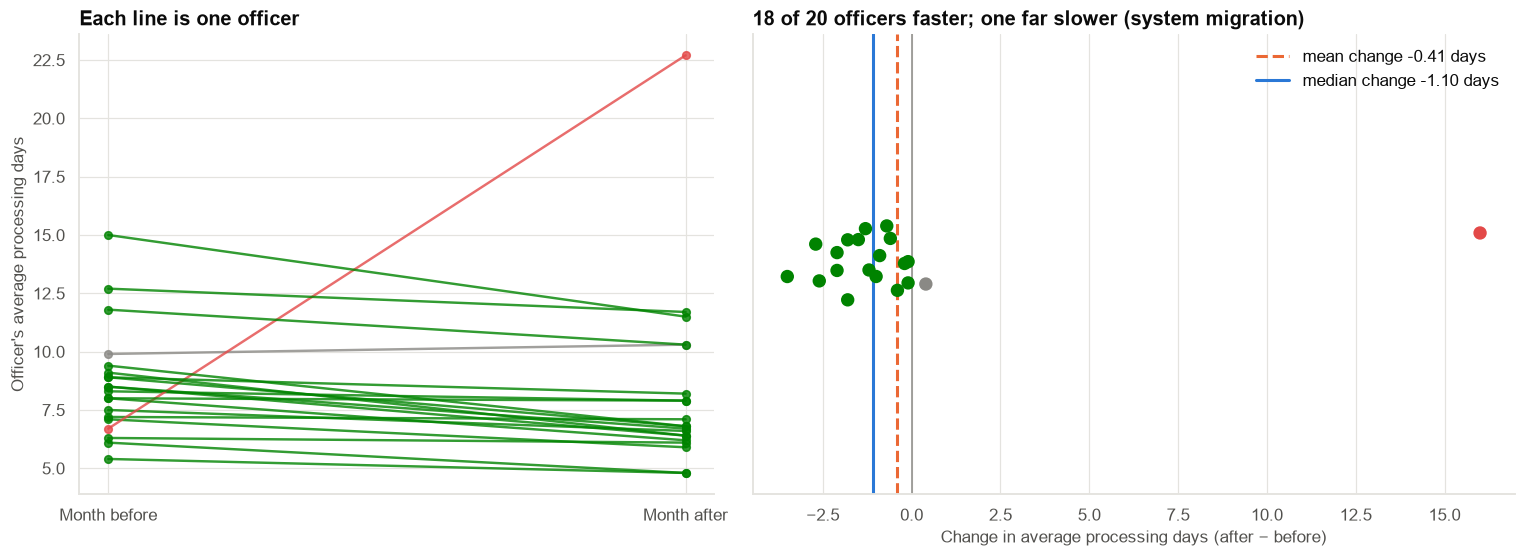

In [8]:
pilot["change"] = pilot["days_after"] - pilot["days_before"]
pilot["pct_change"] = 100 * pilot["change"] / pilot["days_before"]
display(pilot.sort_values("change").round(2))
print(f"Mean change {pilot['change'].mean():+.2f} days; median change {pilot['change'].median():+.2f} days; "
      f"officers who got faster: {(pilot['change'] < 0).sum()} of {len(pilot)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
for _, r in pilot.iterrows():
    col = COLORS["red"] if r["change"] > 5 else (COLORS["green"] if r["change"] < 0 else INK_MUTED)
    ax.plot([0, 1], [r["days_before"], r["days_after"]], "-o", color=col, alpha=0.8, lw=1.6, ms=5)
ax.set_xticks([0, 1], ["Month before", "Month after"])
ax.set(ylabel="Officer's average processing days", title="Each line is one officer")
ax = axes[1]
ax.axvline(0, color=INK_MUTED, lw=1)
ax.scatter(pilot["change"], np.zeros(len(pilot)) + rng.uniform(-0.1, 0.1, len(pilot)), s=60,
           color=[COLORS["red"] if c > 5 else COLORS["green"] if c < 0 else INK_MUTED for c in pilot["change"]], zorder=3)
ax.axvline(pilot["change"].mean(), color=COLORS["orange"], lw=2, ls="--", label=f"mean change {pilot['change'].mean():+.2f} days")
ax.axvline(pilot["change"].median(), color=PRIMARY, lw=2, label=f"median change {pilot['change'].median():+.2f} days")
ax.set_yticks([]); ax.set_ylim(-0.6, 0.6)
ax.set(xlabel="Change in average processing days (after − before)", title=f"{(pilot['change'] < 0).sum()} of {len(pilot)} officers faster; one far slower (system migration)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_fig(fig, "fig03_pilot_changes", PATHS["figures"])
plt.show()

**Observation.** Eighteen of the twenty officers got faster, most by about one to two days (median about 12%); one
was essentially unchanged (+0.4 days). One officer
(LO108) got **16 days slower**: their cases were caught in a system migration that had nothing to do with the
workflow. That single officer pulls the **mean** change down to only about −0.4 days, while the **median** change is
about −1.1 days.

### Section 11 — Four tests on the same pairs

In [9]:
d = pilot["change"].to_numpy()
t_res = stats.ttest_rel(pilot["days_after"], pilot["days_before"])
w_res = stats.wilcoxon(pilot["days_after"], pilot["days_before"])
s_res = stats.binomtest(int((d < 0).sum()), int((d != 0).sum()), 0.5)
# Sign-flip permutation test of the mean change (exact: 2^20 sign patterns would be ~1M; we sample 100,000).
flips = rng.choice([-1, 1], size=(100_000, len(d)))
perm = (flips * np.abs(d)).mean(axis=1)
p_perm = (np.abs(perm) >= abs(d.mean())).mean()
walsh = (d[:, None] + d[None, :])[np.triu_indices(len(d))] / 2
hl = np.median(walsh)                               # Hodges-Lehmann estimate (median of Walsh averages)
boot_hl = [np.median(((s := rng.choice(d, len(d)))[:, None] + s[None, :])[np.triu_indices(len(d))] / 2) for _ in range(3000)]
paired = pd.DataFrame({
    "estimate (days)": [d.mean(), hl, np.median(d), d.mean()],
    "p_value": [t_res.pvalue, w_res.pvalue, s_res.pvalue, p_perm],
    "what it tests": ["mean change = 0 (assumes roughly normal changes)",
                      "changes symmetric around 0 (pseudo-median = 0)", "P(faster) = 50% (direction only)",
                      "mean change = 0, without normality"]},
    index=["Paired t-test", "Wilcoxon signed-rank (Hodges-Lehmann estimate)", "Sign test (median change)", "Sign-flip permutation (mean)"])
t_ci = t_res.confidence_interval()
paired["ci_low"] = [t_ci.low, np.percentile(boot_hl, 2.5), np.nan, np.nan]
paired["ci_high"] = [t_ci.high, np.percentile(boot_hl, 97.5), np.nan, np.nan]
save_table(paired, "paired_tests", PATHS["tables"])
display(paired)

d_wo = np.delete(d, np.argmax(d))
print(f"Without the migration-affected officer: paired t p = {stats.ttest_1samp(d_wo, 0).pvalue:.2g}, "
      f"Wilcoxon p = {stats.wilcoxon(d_wo).pvalue:.2g}, mean change {d_wo.mean():+.2f} days")

,estimate (days),p_value,what it tests,ci_low,ci_high
Paired t-test,-0.4100,0.6512,mean change = 0 (assumes roughly normal changes),-2.2779,1.4579
Wilcoxon signed-rank (Hodges-Lehmann estimate),-1.1000,0.0026,changes symmetric around 0 (pseudo-median = 0),-1.6500,-0.5500
Sign test (median change),-1.1000,0.0004,P(faster) = 50% (direction only),NaN,NaN
Sign-flip permutation (mean),-0.4100,0.8572,"mean change = 0, without normality",NaN,NaN


Without the migration-affected officer: paired t p = 4.1e-05, Wilcoxon p = 0.00027, mean change -1.27 days


**Observation.**
- **Paired t-test:** p ≈ 0.65. The mean change (−0.4 days) has a confidence interval spanning zero, because the
  outlier inflates the standard deviation of the changes about fourfold.
- **Sign-flip permutation test of the mean:** also not significant. It drops the normality assumption, but still tests
  the **mean**, which the outlier drags towards zero.
- **Wilcoxon signed-rank:** p ≈ 0.003. The Hodges-Lehmann estimate of the typical change is about **−1.1 days**
  (bootstrap 95% CI about −1.65 to −0.55).
- **Sign test:** p < 0.001. 18 of 20 officers improved; the test only uses the direction.
- Removing the migration officer, every test is highly significant.

**Interpretation.** For a **typical officer**, the workflow cut processing time by about a day (roughly 12%). The
analyst's "not significant" came from the paired t-test, which answers a question about the **mean** and is very
sensitive to one extreme pair in a sample of 20.

**But do not simply delete the outlier.** The migration slowdown is real and happened to a real officer. The honest
summary is: *"The workflow reduced typical processing time by about one day; 18 of 20 officers got faster; one officer's
cases were delayed by an unrelated system migration, which should be fixed before roll-out."* Report both.

**Which paired test?**

| Test | Uses | Good when | Weak when |
|---|---|---|---|
| Paired t | values of the differences | differences roughly normal, or n large (≥ 30–50) | small n with outliers or strong skew |
| **Wilcoxon signed-rank** | ranks of |differences| and signs | small n, outliers, roughly symmetric differences | very skewed differences (tests pseudo-median) |
| Sign test | signs only | any shape; ordinal outcomes; robust to anything | low power: ignores how large the changes are |
| Permutation (sign-flip) | values, no normality | small n, want the mean without normality | still sensitive to outliers (mean) |

## Section 12 — When does each test win? A simulation

Paired t  Wilcoxon   Sign
distribution of changes scenario                                           
normal                  no effect (type I error)    0.0510    0.0490 0.0305
                        real shift (power)          0.7205    0.7035 0.5345
heavy tails (t, 2 df)   no effect (type I error)    0.0400    0.0475 0.0470
                        real shift (power)          0.3270    0.4445 0.4170
5% outliers             no effect (type I error)    0.0295    0.0540 0.0455
                        real shift (power)          0.3990    0.5920 0.4755

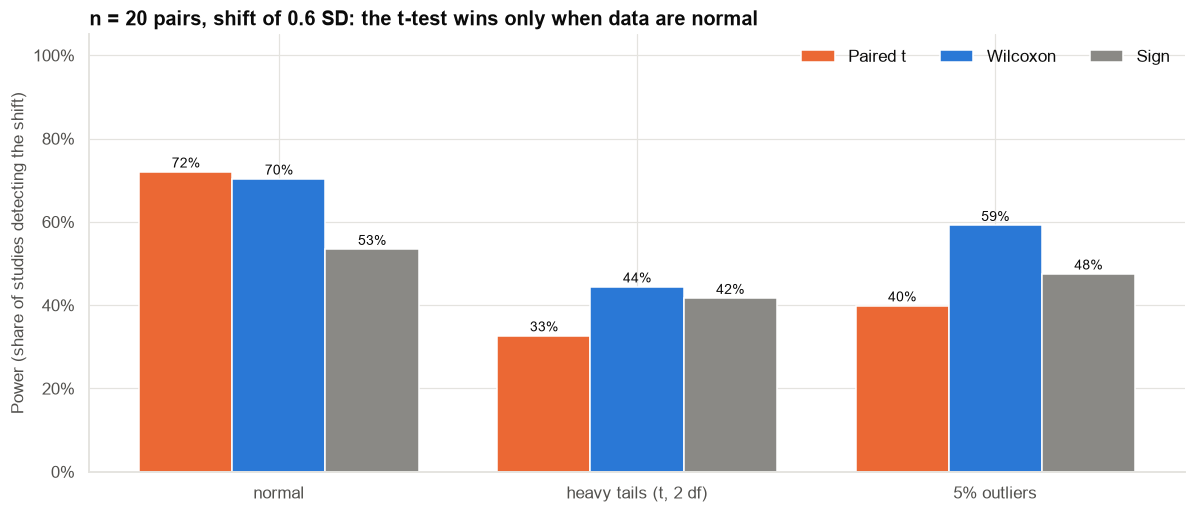

In [10]:
def sim(dist, shift, n=20, reps=2000):
    hits = {"Paired t": 0, "Wilcoxon": 0, "Sign": 0}
    for _ in range(reps):
        if dist == "normal":
            x = rng.normal(0, 1, n)
        elif dist == "heavy tails (t, 2 df)":
            x = rng.standard_t(2, n)
        else:  # occasional big outlier
            x = rng.normal(0, 1, n) + np.where(rng.random(n) < 0.05, rng.normal(0, 15, n), 0)
        x = x + shift
        hits["Paired t"] += stats.ttest_1samp(x, 0).pvalue < 0.05
        hits["Wilcoxon"] += stats.wilcoxon(x).pvalue < 0.05
        hits["Sign"] += stats.binomtest(int((x > 0).sum()), n, 0.5).pvalue < 0.05
    return {k: v / reps for k, v in hits.items()}

sim_rows = []
for dist in ["normal", "heavy tails (t, 2 df)", "5% outliers"]:
    for shift, lab in [(0.0, "no effect (type I error)"), (0.6, "real shift (power)")]:
        sim_rows.append({"distribution of changes": dist, "scenario": lab, **sim(dist, shift)})
sim_tbl = pd.DataFrame(sim_rows).set_index(["distribution of changes", "scenario"])
save_table(sim_tbl, "test_choice_simulation", PATHS["tables"])
display(sim_tbl)

fig, ax = plt.subplots(figsize=(11, 4.8))
pw = sim_tbl.xs("real shift (power)", level="scenario")
x = np.arange(len(pw))
for i, (col, c) in enumerate(zip(pw.columns, [COLORS["orange"], PRIMARY, INK_MUTED])):
    ax.bar(x + (i - 1) * 0.26, pw[col], width=0.26, color=c, label=col)
    for xi, v in zip(x, pw[col]):
        ax.text(xi + (i - 1) * 0.26, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, pw.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(ylabel="Power (share of studies detecting the shift)", ylim=(0, 1.05),
       title="n = 20 pairs, shift of 0.6 SD: the t-test wins only when data are normal")
ax.legend(frameon=False, ncol=3, loc="upper right")
fig.tight_layout()
save_fig(fig, "fig04_power_simulation", PATHS["figures"])
plt.show()

**Observation.**
- With **no effect**, all three tests keep their false-alarm rate close to or below 5% in every scenario (the t-test
  becomes conservative with outliers: it rarely rejects anything).
- With **normal** changes, the t-test has slightly more power than Wilcoxon (Wilcoxon is about 95% as efficient),
  and the sign test is clearly weaker.
- With **heavy tails** or **occasional outliers**, Wilcoxon beats the t-test by about 12–19 percentage points of power
  (44% vs 33%; 59% vs 40%), and even the sign test beats it.

**Interpretation.** The non-parametric tests are not a "weaker fallback". When data have outliers or heavy tails,
they are **more** powerful. When data are normal, they lose very little. That is why Wilcoxon is a sensible default
for small paired samples of operational data.

## Section 13 — Decision framework: parametric or non-parametric?

**Step 1: What is the question?** (the estimand)
- About **totals, costs, averages per customer** (₹ that add up)? → the **mean** matters → t-test / ANOVA (with
  bootstrap or robust SEs if skewed). Ranks would answer the wrong question.
- About the **typical** case, or "is A usually larger than B"? → medians / rank tests.

**Step 2: What does the data look like?**

| Data | n per group | Recommended |
|---|---|---|
| Roughly normal, no outliers | any | t-test / ANOVA (Welch versions by default) |
| Skewed but no extreme outliers | large (≥ 30–50) | t-test / ANOVA still fine for means (CLT); or log scale |
| Skewed with outliers | small | **Mann-Whitney / Kruskal-Wallis / Wilcoxon**, or log scale |
| Ordinal (ratings 1–5) | any | Rank tests; or ordinal regression |
| Positive, multiplicative (times, amounts) | any | Log scale (geometric means) or rank tests |
| Paired | any | Paired versions: paired t, **Wilcoxon signed-rank**, sign test |
| Want a mean without normality | small | Bootstrap or permutation test |

**Step 3: Report effect sizes the test matches.**
- Mean tests → mean difference with CI.
- Rank tests → median difference / Hodges-Lehmann with CI, probability of superiority, ε² or rank-biserial r.

**Step 4: Choose before you test.** Running several tests and reporting the significant one inflates false positives.

## Section 14 — Results

In [11]:
summary = pd.DataFrame({"Value": [
    f"medians {desc['median'].min():.1f}–{desc['median'].max():.1f} days; means {desc['mean'].min():.1f}–{desc['mean'].max():.1f} (stuck loans)",
    f"ANOVA p = {an.pvalue:.2f}; Welch p = {we.pvalue:.3f}; log-ANOVA p = {fmt_p(lg.pvalue)}; Kruskal-Wallis p = {fmt_p(kw.pvalue)} (ε² = {eps2:.2f})",
    f"{int(dunn['significant (Holm, 5%)'].sum())} of 10 pairs significant (Holm); Panvel and Thane slower than Andheri/Borivali/Vashi",
    f"mean {d.mean():+.2f} days, median {np.median(d):+.2f}, Hodges-Lehmann {hl:+.2f} days; {(d < 0).sum()} of {len(d)} officers faster".replace("mean -", "mean −").replace("median -", "median −").replace("Hodges-Lehmann -", "Hodges-Lehmann −"),
    f"paired t p = {t_res.pvalue:.2f}; Wilcoxon p = {w_res.pvalue:.3f}; sign test p = {fmt_p(s_res.pvalue)}; permutation p = {p_perm:.2f}",
]}, index=["Branch times", "Branch tests", "Post-hoc (Dunn)", "Workflow change", "Workflow tests"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Branch times,medians 6.0–10.4 days; means 8.1–14.4 (stuck l...
Branch tests,ANOVA p = 0.10; Welch p = 0.125; log-ANOVA p =...
Post-hoc (Dunn),6 of 10 pairs significant (Holm); Panvel and T...
Workflow change,"mean −0.41 days, median −1.10, Hodges-Lehmann ..."
Workflow tests,paired t p = 0.65; Wilcoxon p = 0.003; sign te...


## Section 15 — Interpretation

- **Branches:** typical processing times differ clearly. Panvel and Thane are slower (medians about 8–10 days vs about
  6–7 elsewhere). Stuck loans occur everywhere and hide the difference from mean-based tests.
- **Workflow:** for a typical officer, processing time fell by about a day (≈ 12%), and 18 of 20 officers improved.
  The mean-based test missed it because of one migration-affected officer.
- **Method:** the test must match the question (typical vs average) and the data (small, skewed, outliers, paired).

## Section 16 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "A loan at Panvel takes longer than one at Andheri about three times out of four." | "Panvel's average loan takes X days longer" (means are dominated by stuck loans). |
| "The workflow cut a typical officer's processing time by about a day; 18 of 20 improved." | "The workflow had no effect" (based on the paired t-test). |
| "One officer was delayed by the system migration." | "The workflow made one officer 16 days slower." |
| "Rank tests show the branches differ in typical processing time." | "The branch medians are significantly different" if shapes differed a lot (rank tests compare distributions). |

## Section 17 — Business interpretation

- **Branches:** investigate Panvel's and Thane's typical process (staffing, credit-approval queue), separately from the
  stuck-loan problem, which affects all branches.
- **Workflow:** roll it out, after fixing the migration issue that delayed one officer's cases.
- **Reporting:** track **median** processing time and the **share of loans over 20 days** as two separate KPIs.

## Section 18 — Limitations

- Branch comparison is observational: case mix (loan size, customer type) may differ by branch.
- The pilot has no control group: some improvement could be seasonal or a "being watched" effect. A stepped roll-out
  with a comparison group would be stronger.
- 20 officers and one month before/after.
- Synthetic data.

## Section 19 — Final recommendation

> **Roll out the new workflow** (typical saving ≈ 1 day per loan; 18 of 20 officers faster), after resolving the
> migration problem. **Prioritise process reviews at Panvel and Thane.** In operational reporting, use **medians and
> rank tests** for processing times, and track stuck loans as a separate KPI.

## Section 20 — What would I do next?

1. Run the roll-out as a **stepped-wedge** design (branches adopt in random order) to estimate the effect against a
   concurrent control.
2. Model processing time with **quantile regression** or a **survival model** (time to disbursement; Case 26) with
   loan characteristics, to check whether branch differences survive case-mix adjustment.
3. Build a stuck-loan early-warning flag (missing documents on day 3).
4. Continue to **Case 16** (outliers: error, fraud, VIP or rare event?).